## Імпорт бібліотек
Завантажуємо стандартні бібліотеки для обробки даних, побудови графіків та машинного навчання зі scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

fig_dir = os.path.abspath(os.path.join(os.getcwd(), 'figures'))
if not os.path.exists(fig_dir):
    fig_dir = os.path.abspath(os.path.join(os.getcwd(), 'laba3', 'figures'))
os.makedirs(fig_dir, exist_ok=True)

## Завантаження датасету



In [2]:
raw_data = load_breast_cancer()

df = pd.DataFrame(raw_data.data, columns=raw_data.feature_names)
df['target'] = raw_data.target
df['target_name'] = df['target'].map({0: 'Злоякісна (0)', 1: 'Доброякісна (1)'})

print(f"Розмірність датасету: {df.shape[0]} рядків та {df.shape[1] - 2} ознак.")
print(df.head())

Розмірність датасету: 569 рядків та 30 ознак.
   mean radius  mean texture  ...  target    target_name
0        17.99         10.38  ...       0  Злоякісна (0)
1        20.57         17.77  ...       0  Злоякісна (0)
2        19.69         21.25  ...       0  Злоякісна (0)
3        11.42         20.38  ...       0  Злоякісна (0)
4        20.29         14.34  ...       0  Злоякісна (0)

[5 rows x 32 columns]


## Дослідницький аналіз даних
Перевіряємо структуру таблиці

In [3]:
print("Інформація про набір даних:")
df.info()

print("\nКількість пропущених значень:", df.isnull().sum().sum())

Інформація про набір даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14

### Порівняння масштабів ознак


In [4]:
desc = df.describe().T[['mean', 'std', 'min', '50%', 'max']]

sample_features = ['mean radius', 'mean smoothness', 'mean area', 'worst area', 'mean fractal dimension']
print("Показники для вибраних ознак:")
print(desc.loc[sample_features])

Показники для вибраних ознак:
                              mean         std  ...        50%         max
mean radius              14.127292    3.524049  ...   13.37000    28.11000
mean smoothness           0.096360    0.014064  ...    0.09587     0.16340
mean area               654.889104  351.914129  ...  551.10000  2501.00000
worst area              880.583128  569.356993  ...  686.50000  4254.00000
mean fractal dimension    0.062798    0.007060  ...    0.06154     0.09744

[5 rows x 5 columns]


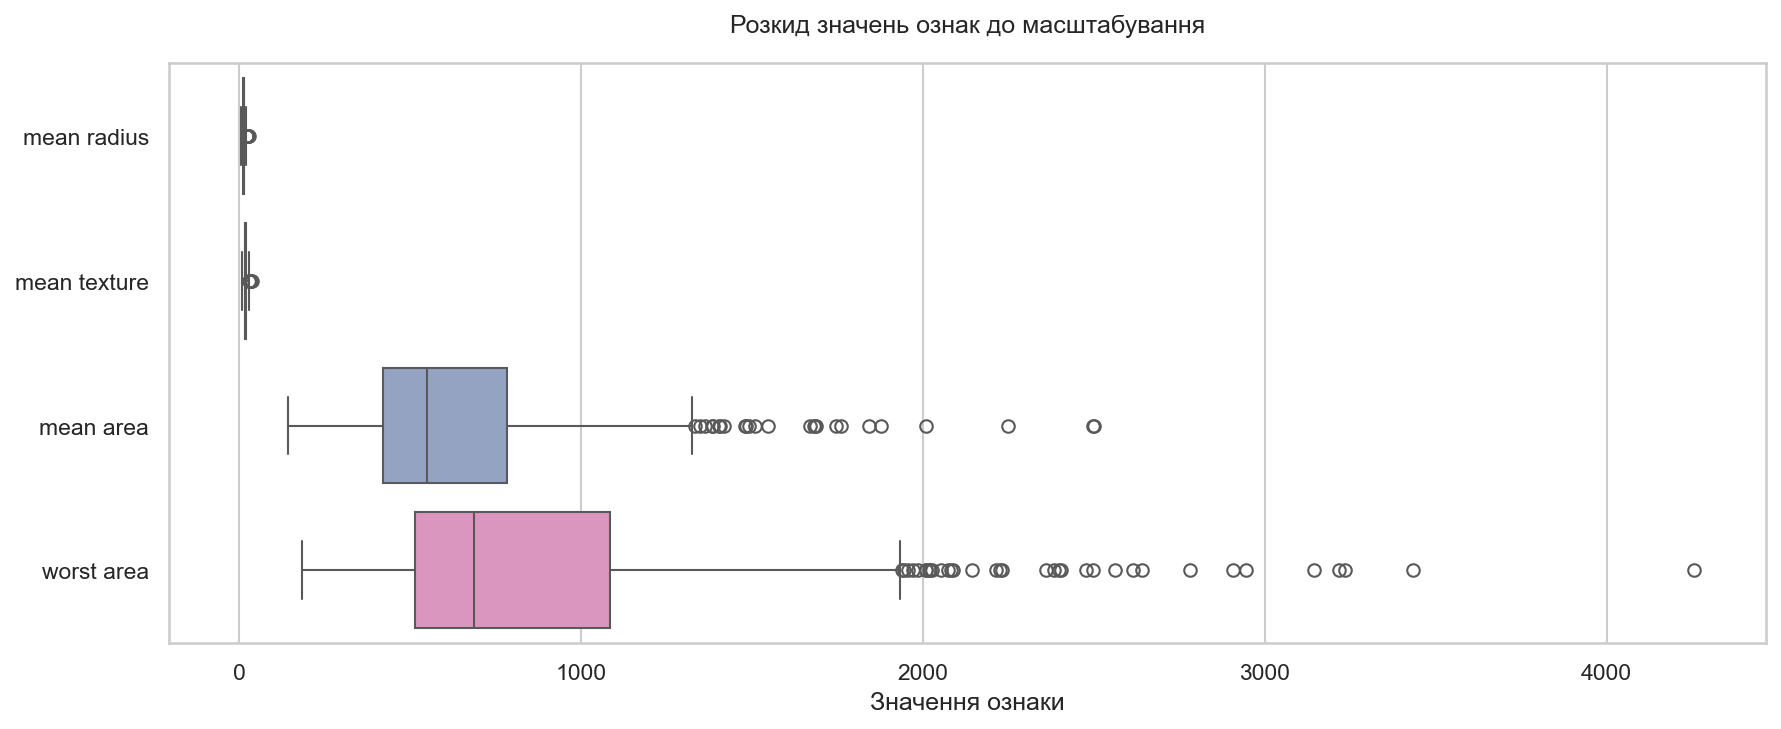

In [5]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[['mean radius', 'mean texture', 'mean area', 'worst area']], orient='h', palette='Set2')
plt.title("Розкид значень ознак до масштабування", pad=15)
plt.xlabel("Значення ознаки")
plt.tight_layout()
plt.savefig(f'{fig_dir}/eda_unscaled_boxplots.png', dpi=300)
plt.show()

### Перевірка балансу класів
Співвідношення доброякісних і злоякісних пухлин у вибірці

                 Кількість  Частка (%)
target_name                           
Доброякісна (1)        357       62.74
Злоякісна (0)          212       37.26


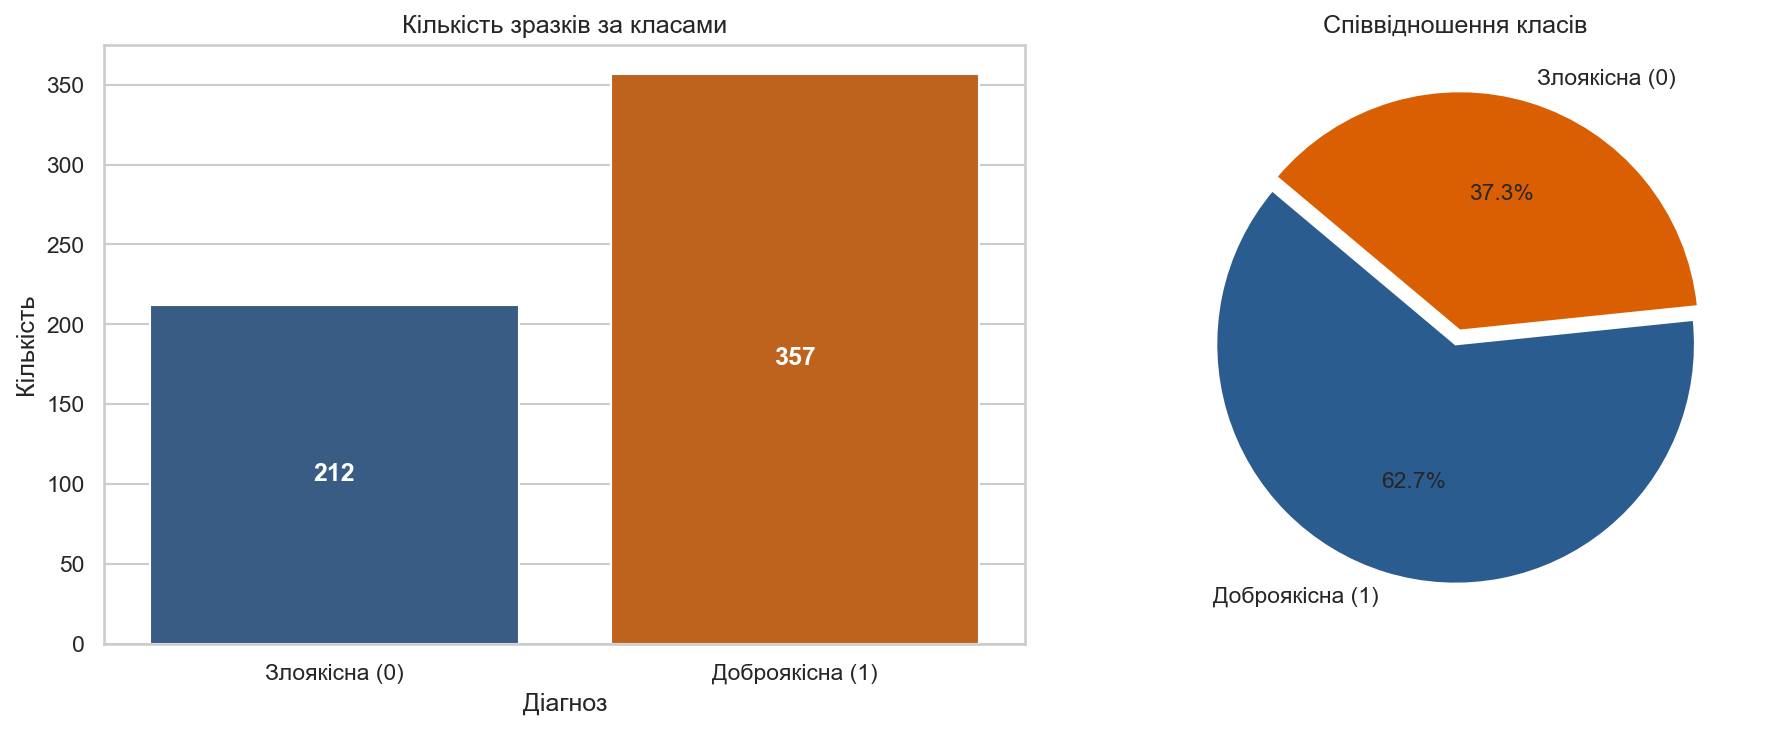

In [6]:
class_counts = df['target_name'].value_counts()
class_pct = df['target_name'].value_counts(normalize=True) * 100

balance_df = pd.DataFrame({'Кількість': class_counts, 'Частка (%)': class_pct.round(2)})
print(balance_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x='target_name', ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title("Кількість зразків за класами")
axes[0].set_xlabel("Діагноз")
axes[0].set_ylabel("Кількість")
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

axes[1].pie(class_counts, labels=class_counts.index, autopct='%1.1f%%',
            startangle=140, colors=['#2b5c8f', '#d95f02'], explode=(0, 0.06))
axes[1].set_title("Співвідношення класів")

plt.tight_layout()
plt.savefig(f'{fig_dir}/eda_class_balance.png', dpi=300)
plt.show()

### Кореляція між ознаками
Теплова карта, щоб побачити лінійні зв'язки між радіусом периметром та площею

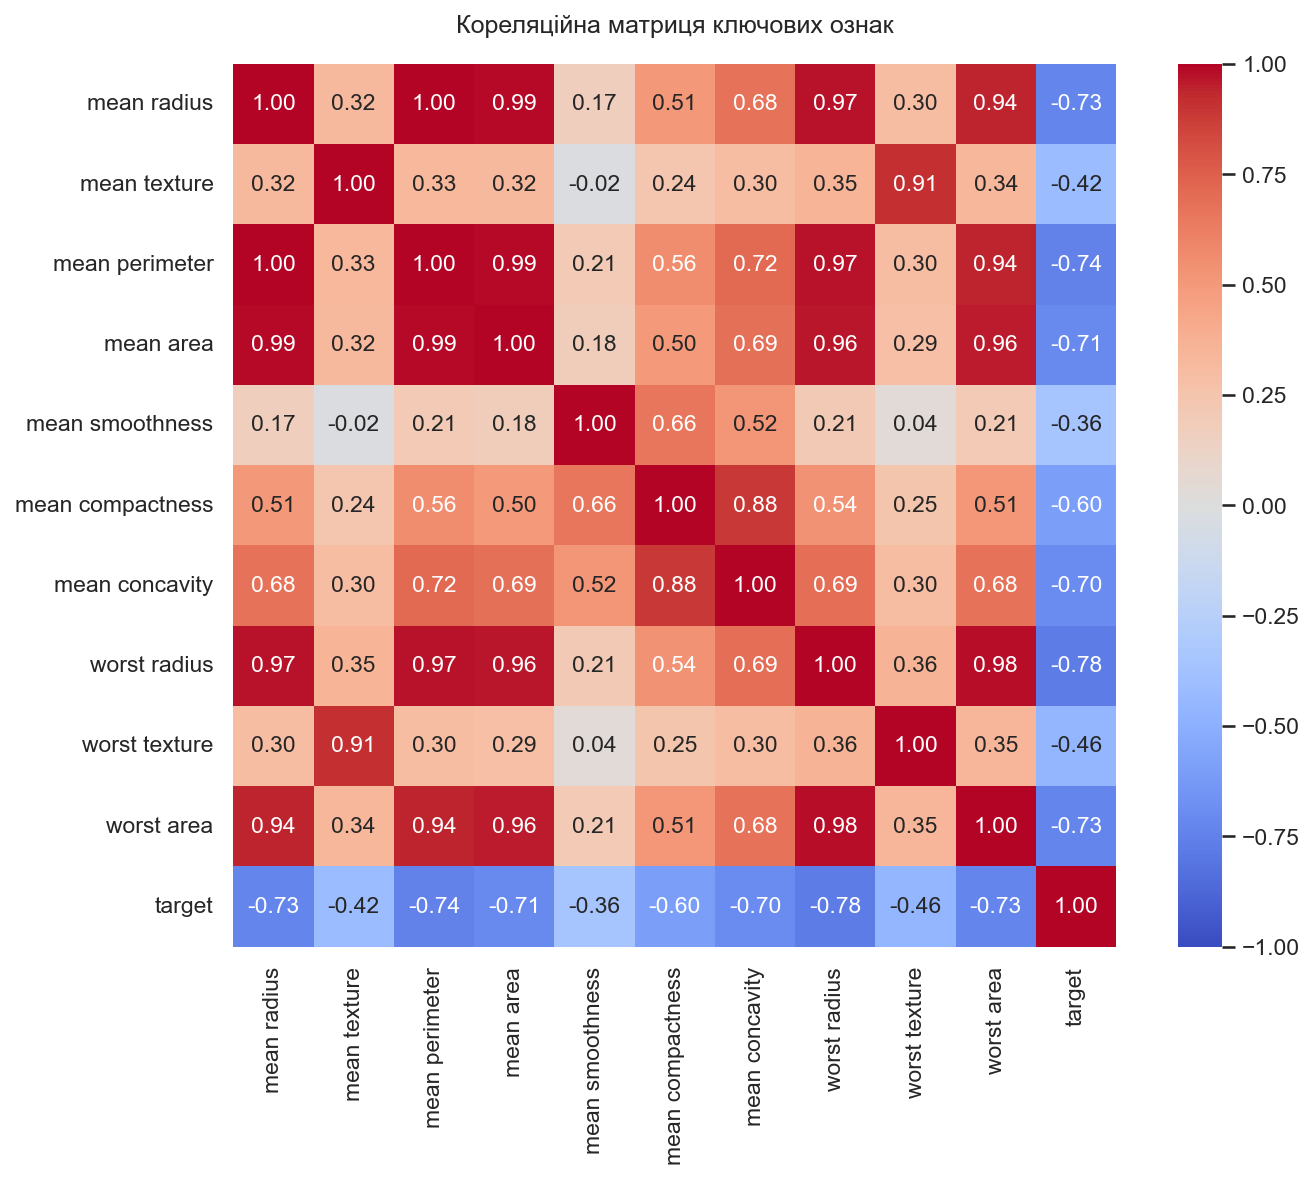

In [7]:
key_features = [
    'mean radius', 'mean texture', 'mean perimeter', 'mean area',
    'mean smoothness', 'mean compactness', 'mean concavity',
    'worst radius', 'worst texture', 'worst area', 'target'
]

plt.figure(figsize=(10, 8))
corr_matrix = df[key_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title("Кореляційна матриця ключових ознак", pad=15)
plt.tight_layout()
plt.savefig(f'{fig_dir}/eda_correlation_heatmap.png', dpi=300)
plt.show()

## Розбиття вибірки та масштабування


In [8]:
X = df.drop(columns=['target', 'target_name'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Кількість об'єктів для навчання: {X_train.shape[0]}")
print(f"Кількість об'єктів для тесту:     {X_test.shape[0]}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Середнє тренувальних даних після скалера: {X_train_scaled.mean():.4f}")
print(f"Дисперсія тренувальних даних після скалера: {X_train_scaled.std():.4f}")

Кількість об'єктів для навчання: 455
Кількість об'єктів для тесту:     114
Середнє тренувальних даних після скалера: -0.0000
Дисперсія тренувальних даних після скалера: 1.0000


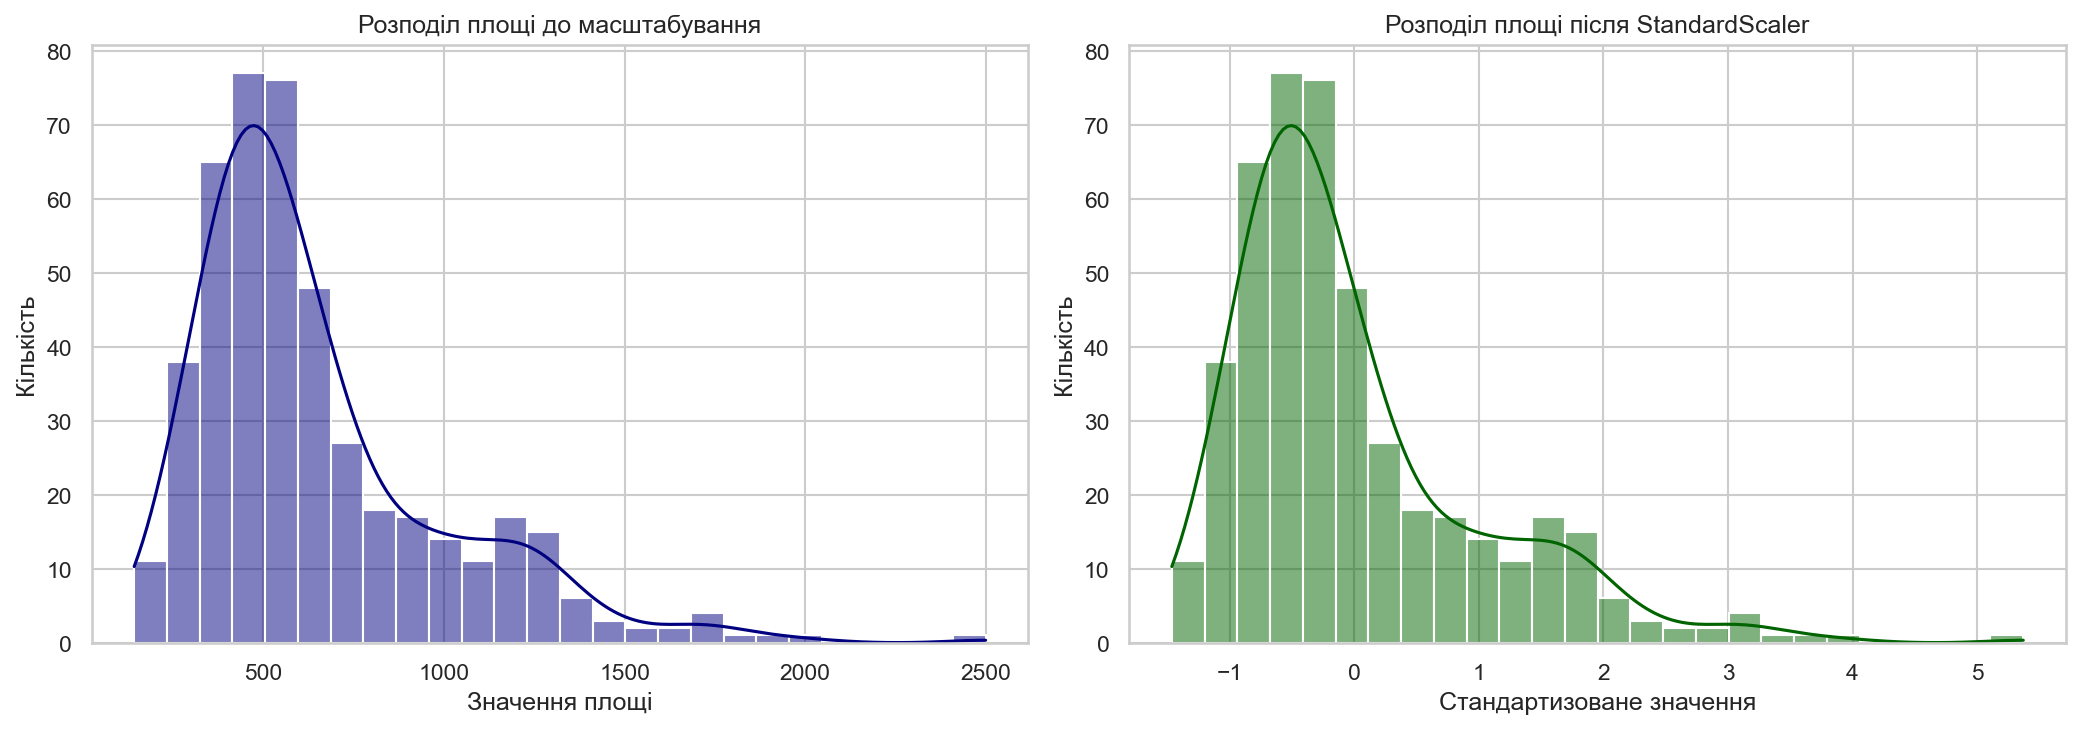

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(X_train['mean area'], kde=True, ax=axes[0], color='navy')
axes[0].set_title("Розподіл площі до масштабування")
axes[0].set_xlabel("Значення площі")
axes[0].set_ylabel("Кількість")

sns.histplot(X_train_scaled[:, X.columns.get_loc('mean area')], kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title("Розподіл площі після StandardScaler")
axes[1].set_xlabel("Стандартизоване значення")
axes[1].set_ylabel("Кількість")

plt.tight_layout()
plt.savefig(f'{fig_dir}/scaling_comparison.png', dpi=300)
plt.show()

## Навчання моделей класифікації
Тренуємо чотири варіанти моделей
1. Логістична регресія
2. Метод опорних векторів з лінійним ядром
3. Метод опорних векторів з радіальним ядром
4. Випадковий ліс

In [10]:
models = {
    'Логістична регресія': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'X_tr': X_train_scaled,
        'X_te': X_test_scaled,
        'scaled': True
    },
    'SVM з лінійним ядром': {
        'model': SVC(kernel='linear', probability=True, random_state=42),
        'X_tr': X_train_scaled,
        'X_te': X_test_scaled,
        'scaled': True
    },
    'SVM з радіальним ядром': {
        'model': SVC(kernel='rbf', probability=True, random_state=42),
        'X_tr': X_train_scaled,
        'X_te': X_test_scaled,
        'scaled': True
    },
    'Випадковий ліс': {
        'model': RandomForestClassifier(n_estimators=100, random_state=42),
        'X_tr': X_train,
        'X_te': X_test,
        'scaled': False
    }
}

predictions = {}
probabilities = {}

for name, cfg in models.items():
    clf = cfg['model']
    clf.fit(cfg['X_tr'], y_train)
    predictions[name] = clf.predict(cfg['X_te'])
    probabilities[name] = clf.predict_proba(cfg['X_te'])[:, 1]
    print(f"Модель '{name}' успішно натреновано.")

Модель 'Логістична регресія' успішно натреновано.
Модель 'SVM з лінійним ядром' успішно натреновано.
Модель 'SVM з радіальним ядром' успішно натреновано.
Модель 'Випадковий ліс' успішно натреновано.


## Оцінка моделей та матриці помилок
Будуємо матриці помилок для кожної з чотирьох моделей

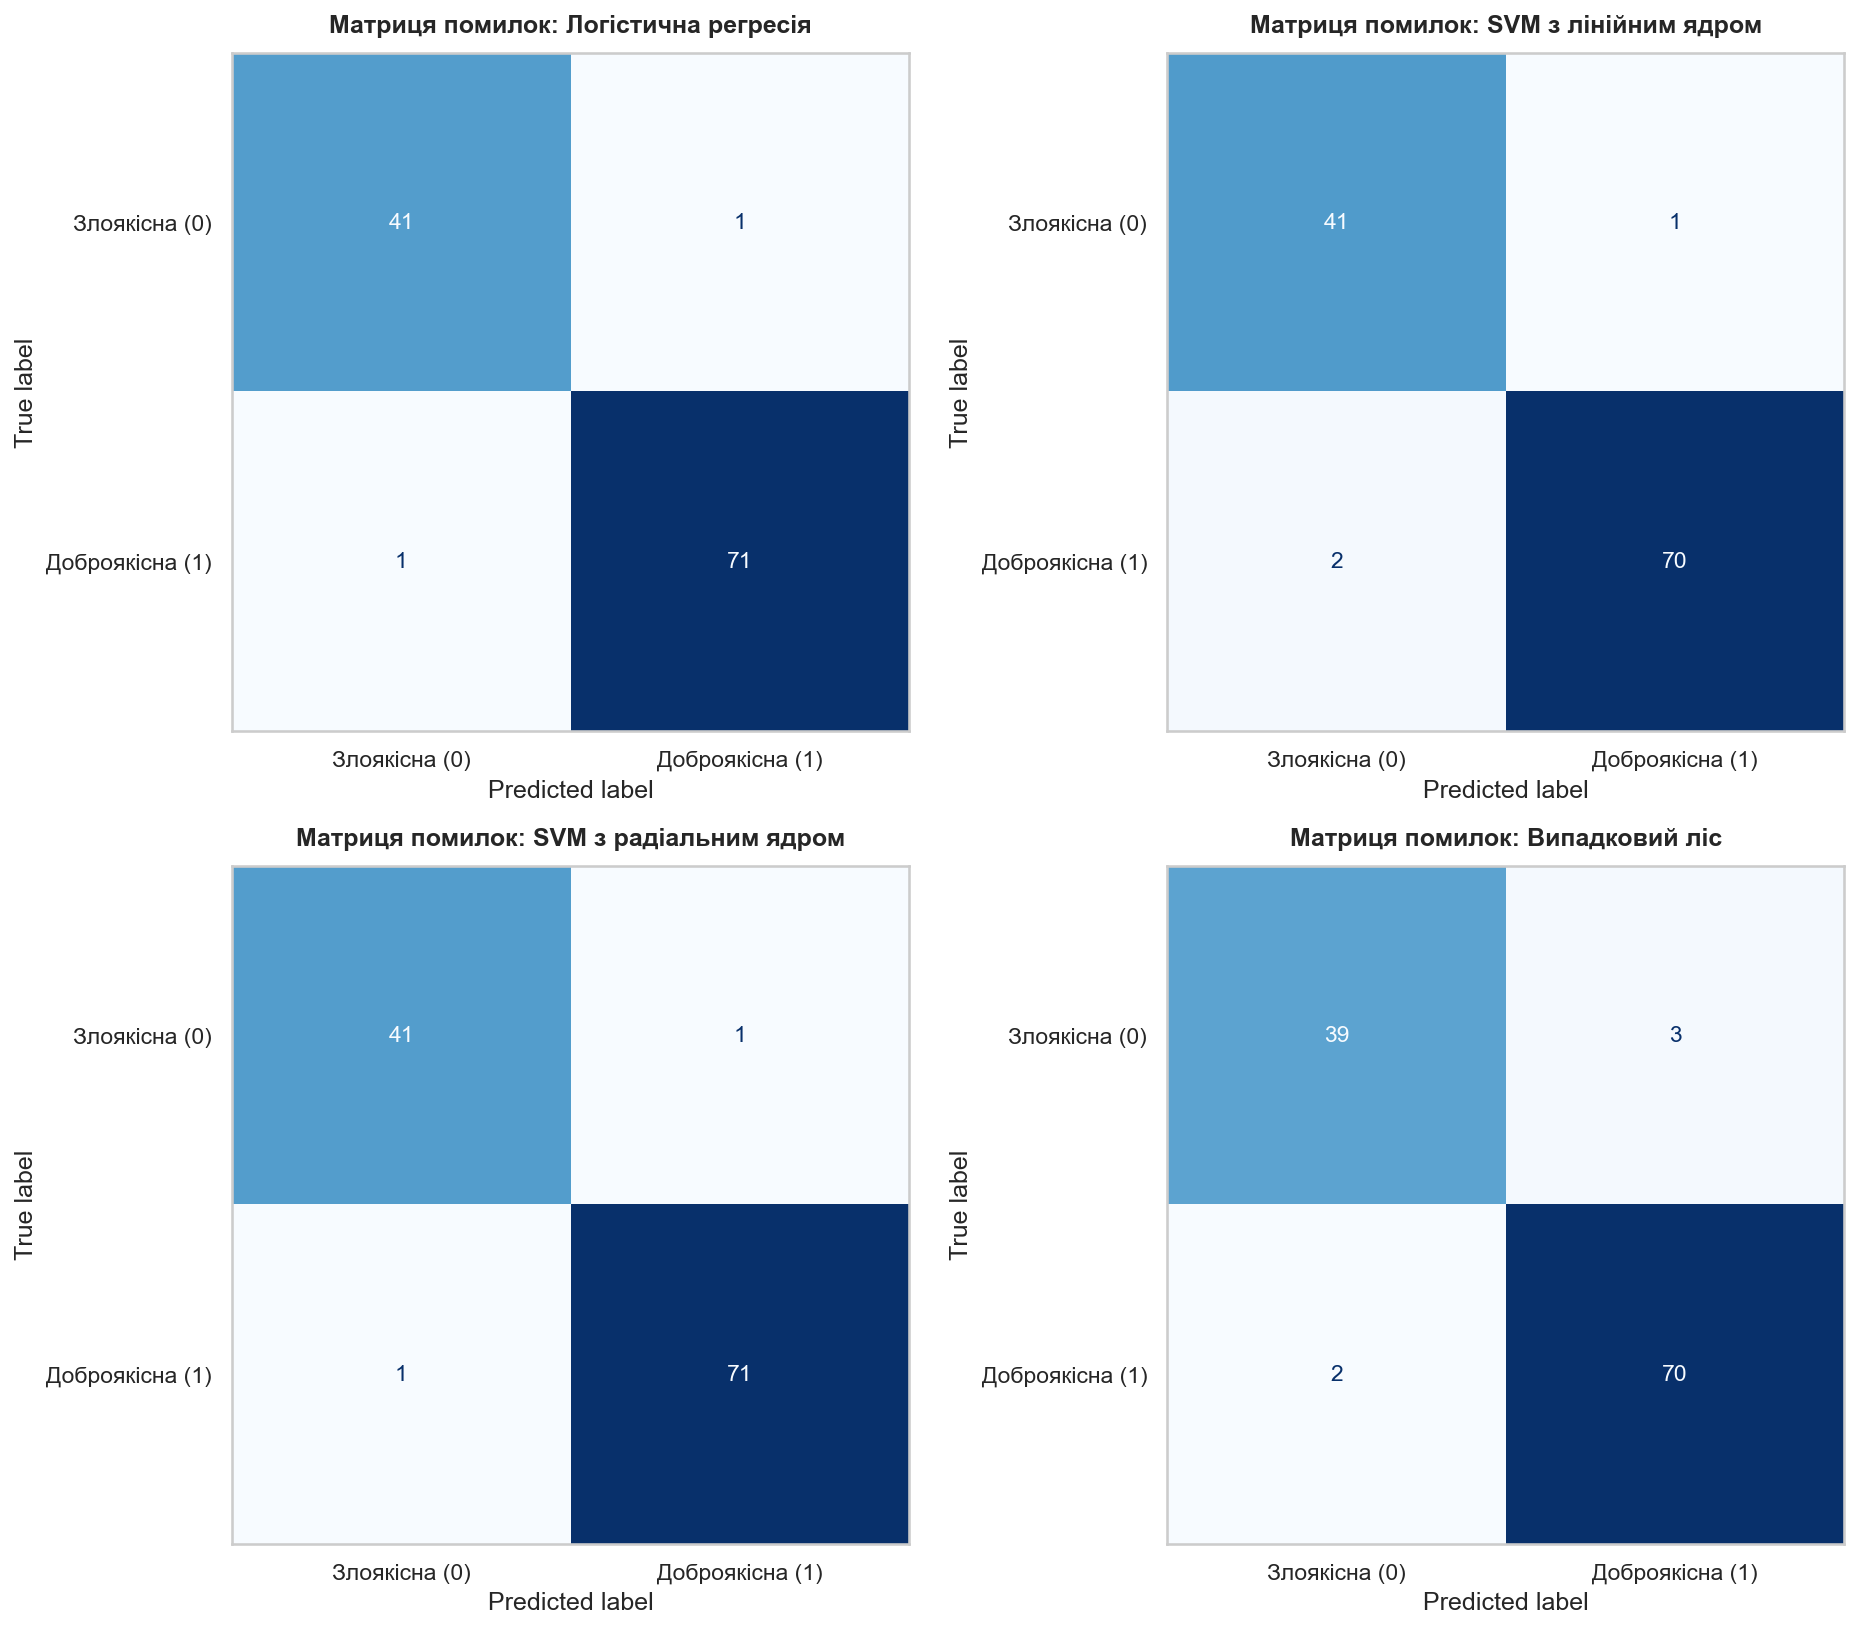

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

class_labels = ['Злоякісна (0)', 'Доброякісна (1)']

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False, values_format='d')
    axes[idx].set_title(f"Матриця помилок: {name}", pad=10, fontweight='bold')
    axes[idx].grid(False)

plt.tight_layout()
plt.savefig(f'{fig_dir}/confusion_matrices_grid.png', dpi=300)
plt.show()

In [12]:
for name, y_pred in predictions.items():
    print(f"\nЗвіт класифікації для моделі {name}:")
    print(classification_report(y_test, y_pred, target_names=['Злоякісна (0)', 'Доброякісна (1)'], digits=4))


Звіт класифікації для моделі Логістична регресія:
                 precision    recall  f1-score   support

  Злоякісна (0)     0.9762    0.9762    0.9762        42
Доброякісна (1)     0.9861    0.9861    0.9861        72

       accuracy                         0.9825       114
      macro avg     0.9812    0.9812    0.9812       114
   weighted avg     0.9825    0.9825    0.9825       114


Звіт класифікації для моделі SVM з лінійним ядром:
                 precision    recall  f1-score   support

  Злоякісна (0)     0.9535    0.9762    0.9647        42
Доброякісна (1)     0.9859    0.9722    0.9790        72

       accuracy                         0.9737       114
      macro avg     0.9697    0.9742    0.9719       114
   weighted avg     0.9740    0.9737    0.9737       114


Звіт класифікації для моделі SVM з радіальним ядром:
                 precision    recall  f1-score   support

  Злоякісна (0)     0.9762    0.9762    0.9762        42
Доброякісна (1)     0.9861    0.9861  

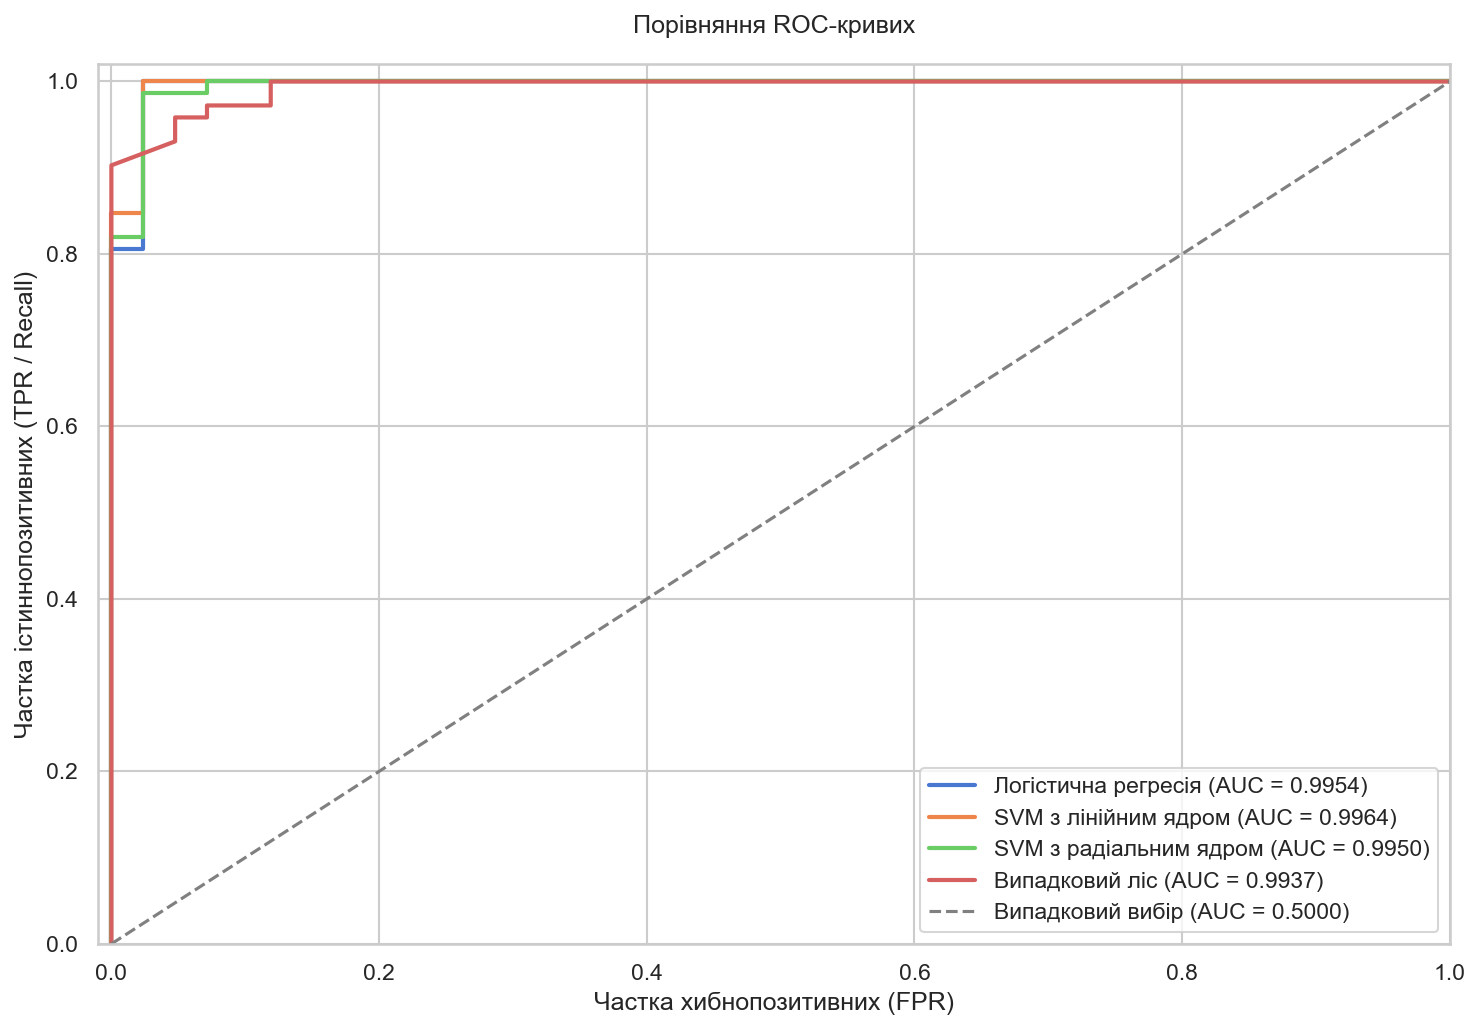

In [13]:
plt.figure(figsize=(10, 7))

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_val:.4f})")

plt.plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle='--', label='Випадковий вибір (AUC = 0.5000)')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel("Частка хибнопозитивних (FPR)")
plt.ylabel("Частка істиннопозитивних (TPR / Recall)")
plt.title("Порівняння ROC-кривих", pad=15)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.savefig(f'{fig_dir}/roc_curves_comparison.png', dpi=300)
plt.show()

## Таблиця результатів


Зведена таблиця результатів:
                Модель         Дані  Точність  Влучність  Повнота  F-міра  ROC-AUC
   Логістична регресія Масштабовані    0.9825     0.9762   0.9762  0.9762   0.9954
  SVM з лінійним ядром Масштабовані    0.9737     0.9535   0.9762  0.9647   0.9964
SVM з радіальним ядром Масштабовані    0.9825     0.9762   0.9762  0.9762   0.9950
        Випадковий ліс  Оригінальні    0.9561     0.9512   0.9286  0.9398   0.9937


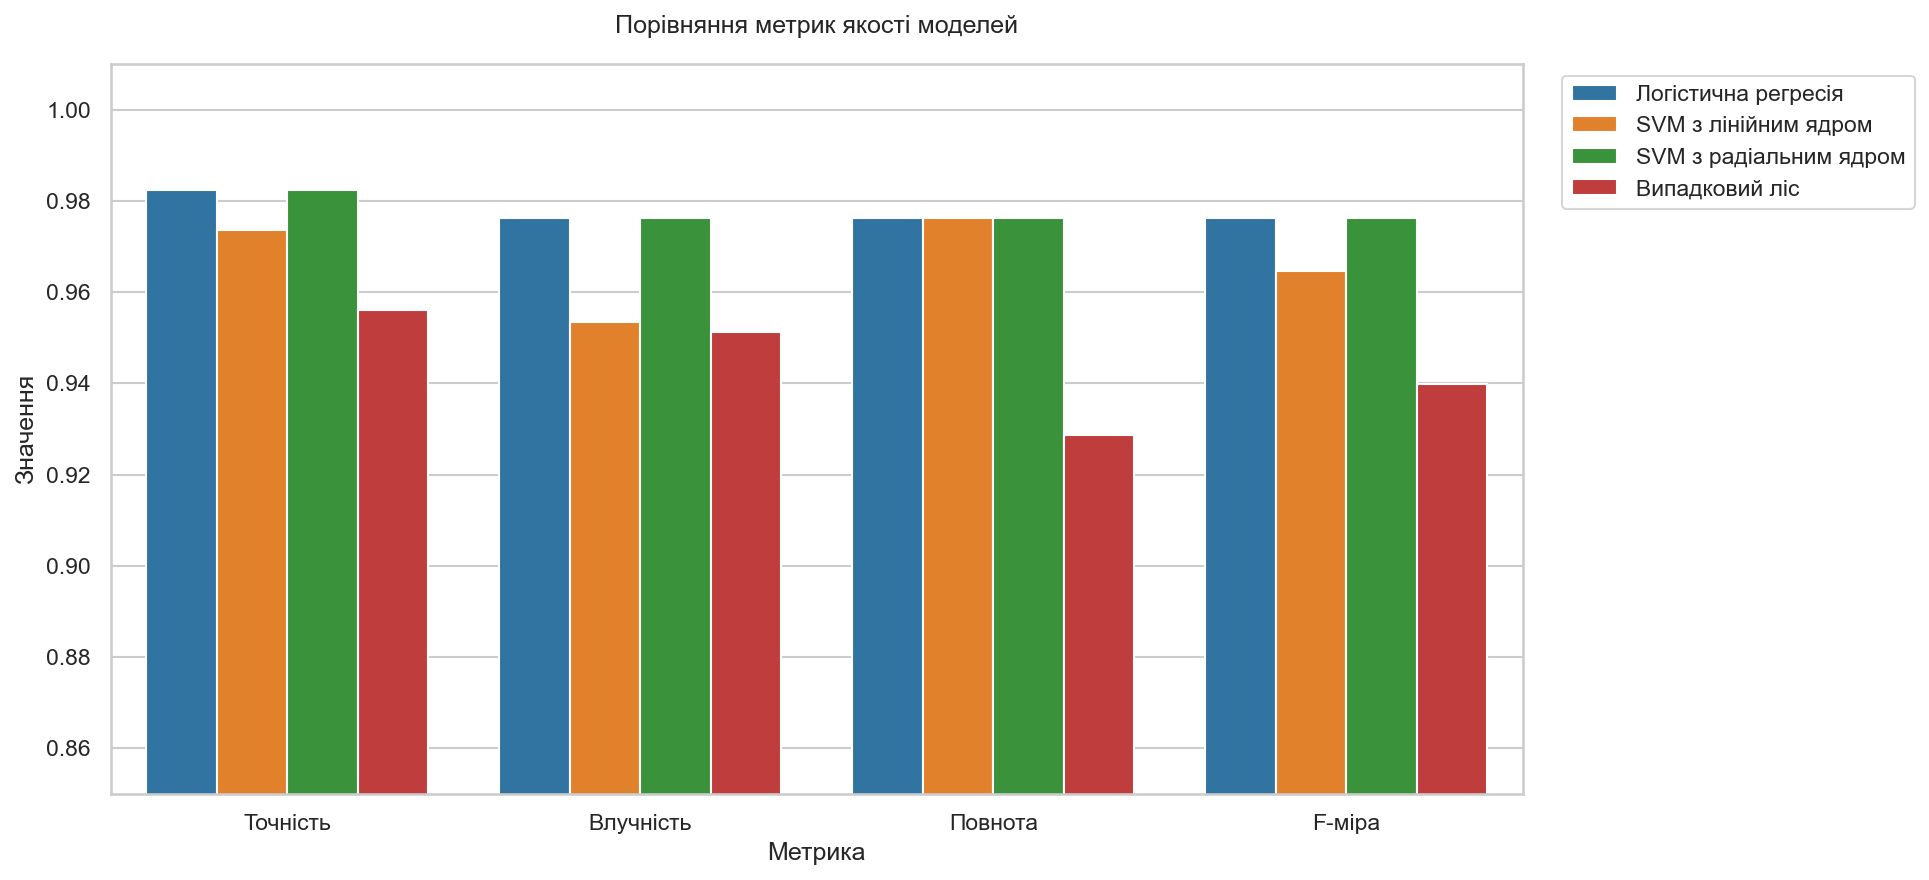

In [14]:
summary_rows = []

for name, y_pred in predictions.items():
    y_prob = probabilities[name]
    
    acc = accuracy_score(y_test, y_pred)
    prec_mal = precision_score(y_test, y_pred, pos_label=0)
    rec_mal = recall_score(y_test, y_pred, pos_label=0)
    f1_mal = f1_score(y_test, y_pred, pos_label=0)
    roc_val = auc(*roc_curve(y_test, y_prob)[:2])
    
    summary_rows.append({
        'Модель': name,
        'Дані': 'Масштабовані' if models[name]['scaled'] else 'Оригінальні',
        'Точність': round(acc, 4),
        'Влучність': round(prec_mal, 4),
        'Повнота': round(rec_mal, 4),
        'F-міра': round(f1_mal, 4),
        'ROC-AUC': round(roc_val, 4)
    })

summary_df = pd.DataFrame(summary_rows)
print("Зведена таблиця результатів:")
print(summary_df.to_string(index=False))

metrics_to_plot = ['Точність', 'Влучність', 'Повнота', 'F-міра']
df_melted = summary_df.melt(id_vars=['Модель'], value_vars=metrics_to_plot, var_name='Метрика', value_name='Значення')

plt.figure(figsize=(13, 6))
sns.barplot(data=df_melted, x='Метрика', y='Значення', hue='Модель', palette='tab10')
plt.ylim(0.85, 1.01)
plt.title("Порівняння метрик якості моделей", pad=15)
plt.ylabel("Значення")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{fig_dir}/metrics_comparison_barchart.png', dpi=300)
plt.show()

### Важливість ознак у випадковому лісі


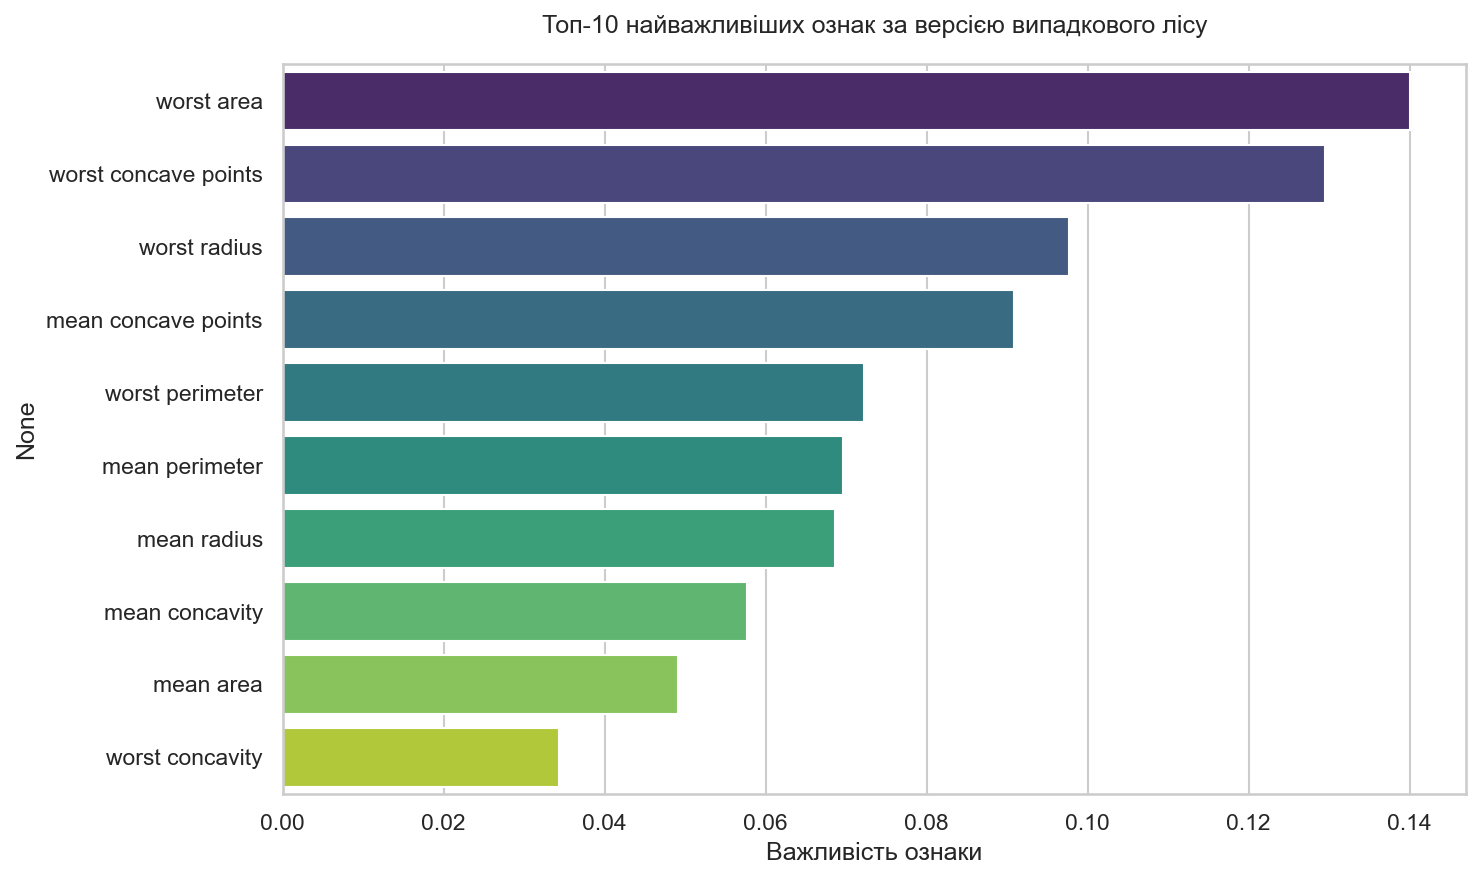

In [15]:
rf_model = models['Випадковий ліс']['model']
importances = rf_model.feature_importances_
feat_importances = pd.Series(importances, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_importances.values, y=feat_importances.index, palette='viridis')
plt.title("Топ-10 найважливіших ознак за версією випадкового лісу", pad=15)
plt.xlabel("Важливість ознаки")
plt.tight_layout()
plt.savefig(f'{fig_dir}/rf_feature_importances.png', dpi=300)
plt.show()

### Перевірка: що станеться, якщо не масштабувати дані для SVM
Натренуємо метод опорних векторів з радіальним ядром на сирих даних і подивимося на зміну результатів

In [16]:
svc_unscaled = SVC(kernel='rbf', random_state=42)
svc_unscaled.fit(X_train, y_train)
y_pred_unscaled = svc_unscaled.predict(X_test)

cm_unscaled = confusion_matrix(y_test, y_pred_unscaled)
rec_unscaled = recall_score(y_test, y_pred_unscaled, pos_label=0)
acc_unscaled = accuracy_score(y_test, y_pred_unscaled)

rec_scaled = summary_df.loc[summary_df['Модель'] == 'SVM з радіальним ядром', 'Повнота'].values[0]
acc_scaled = summary_df.loc[summary_df['Модель'] == 'SVM з радіальним ядром', 'Точність'].values[0]

print("Порівняння SVM з масштабуванням та без нього:")
print(f"Точність з масштабуванням:  {acc_scaled:.4f} | Без масштабування: {acc_unscaled:.4f}")
print(f"Повнота з масштабуванням:   {rec_scaled:.4f} | Без масштабування: {rec_unscaled:.4f}")
print(f"Кількість пропущених злоякісних пухлин:")
print(f"- З масштабуванням: {confusion_matrix(y_test, predictions['SVM з радіальним ядром'])[0, 1]} пацієнт")
print(f"- Без масштабування: {cm_unscaled[0, 1]} пацієнтів (у 6 разів більше помилок!)")

Порівняння SVM з масштабуванням та без нього:
Точність з масштабуванням:  0.9825 | Без масштабування: 0.9298
Повнота з масштабуванням:   0.9762 | Без масштабування: 0.8571
Кількість пропущених злоякісних пухлин:
- З масштабуванням: 1 пацієнт
- Без масштабування: 6 пацієнтів (у 6 разів більше помилок!)
